# 04 — Monte Carlo

So far sampling has been a way to *measure a population*. This notebook is about the
other use, which is stranger and more powerful: sampling as a way to **compute** things
that have no formula.

**The question this notebook answers:** what do you do when the integral has no closed
form?

The answer turns out to be embarrassingly simple. Throw random points at the problem and
count. This is not an approximation technique of last resort — it is how option prices,
risk estimates, physical simulations and Bayesian posteriors are computed every day.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
from scipy import special

from src.config import load_settings, make_rng
from src.evaluation.convergence import (
    fit_convergence_rate,
    logspace_checkpoints,
    rmse_by_n,
)
from src.montecarlo.integration import estimate_pi, expectation, integrate, pi_estimates_at
from src.montecarlo.variance import sqrt_n_band
from src.reporting import save_results
from src.visualisation import (
    plot_convergence,
    plot_darts,
    plot_error_rate,
    plot_function_under_curve,
    save_figure,
)

settings = load_settings()
mc = settings.monte_carlo
rng = make_rng()

print(f"seed = {settings.seed}, darts = {mc.n_darts:,}, "
      f"replicates for the rate study = {mc.n_replicates}")

seed = 20260909, darts = 200,000, replicates for the rate study = 200


## The toy that is not a toy: estimating pi

Take the unit square and the quarter circle inside it. The square has area 1; the quarter
circle has area $\pi/4$. So a dart thrown uniformly at the square lands inside the circle
with probability exactly $\pi/4$.

Throw darts, count the fraction that land inside, multiply by four. No geometry, no
calculus — just counting.

/workspaces/sampling_101/outputs/figures/04_darts.png


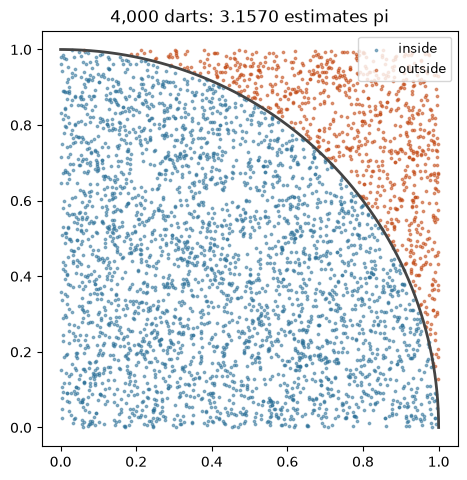

In [2]:
fig = plot_darts(4000, rng)
print(save_figure(fig, "04_darts"))

In [3]:
result = estimate_pi(mc.n_darts, rng)

print(f"darts thrown  : {mc.n_darts:,}")
print(f"estimate      : {result.value:.6f}")
print(f"true pi       : {np.pi:.6f}")
print(f"error         : {result.value - np.pi:+.6f}")
print(f"standard error: {result.se:.6f}")
print(f"\nthe estimate is {abs(result.value - np.pi) / result.se:.2f} standard errors "
      f"from the truth")

darts thrown  : 200,000
estimate      : 3.140100
true pi       : 3.141593
error         : -0.001493
standard error: 0.003674

the estimate is 0.41 standard errors from the truth


Watch it converge. The band is $\pm 1.96\,\sigma/\sqrt{n}$ — where the estimate should be
95% of the time.

/workspaces/sampling_101/outputs/figures/04_pi_convergence.png


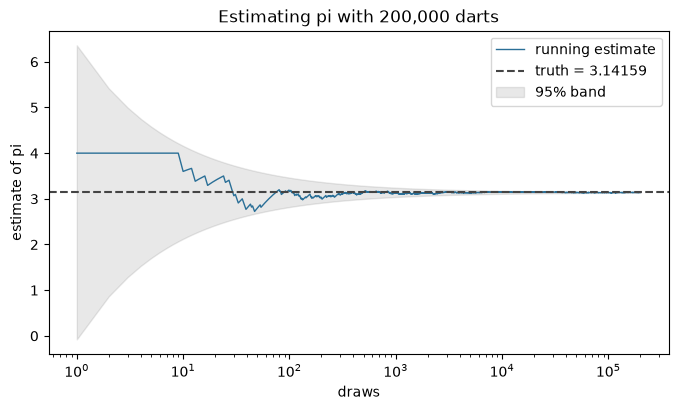

In [4]:
ns = np.arange(1, mc.n_darts + 1)
p = np.pi / 4
band = sqrt_n_band(ns, sigma=4 * np.sqrt(p * (1 - p)))

fig = plot_convergence(
    ns, result.running, float(np.pi),
    f"Estimating pi with {mc.n_darts:,} darts",
    ylabel="estimate of pi",
    band=band,
)
print(save_figure(fig, "04_pi_convergence"))

## The catch: how fast does it converge?

The curve above flattens out, and it is worth being precise about how. Monte Carlo error
falls like $1/\sqrt{n}$ — a rate that is both the method's great virtue (it does not
depend on the dimension of the problem) and its great frustration.

A single run's error is far too noisy to read a rate from. We repeat the whole experiment
200 times and measure the RMSE across replicates at each sample size.

fitted log-log slope: -0.5169   (theory: -0.5)

   n      RMSE over 200 replicates
    100    0.17518
    376    0.08852
  1,414    0.03975
  5,318    0.02265
 20,000    0.01193


/workspaces/sampling_101/outputs/figures/04_error_rate.png


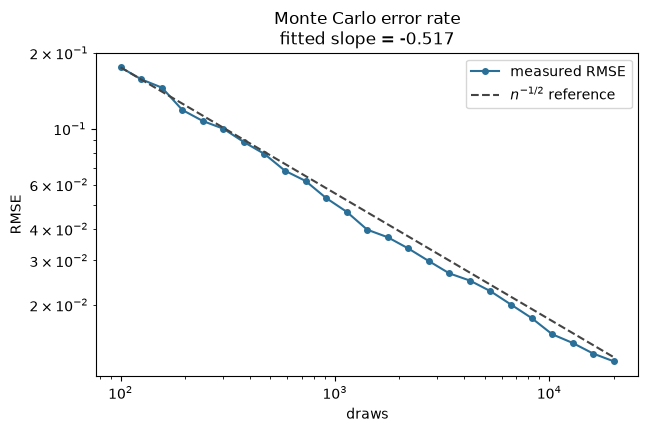

In [5]:
checkpoints = logspace_checkpoints(mc.checkpoint_max, mc.checkpoint_points, n_min=100)
estimates = pi_estimates_at(checkpoints, mc.n_replicates, rng)
rmse = rmse_by_n(estimates, float(np.pi))
slope = fit_convergence_rate(checkpoints, rmse)

print(f"fitted log-log slope: {slope:.4f}   (theory: -0.5)")
print(f"\n   n      RMSE over {mc.n_replicates} replicates")
for n_check, err in zip(checkpoints[::6], rmse[::6], strict=False):
    print(f"{n_check:>7,}    {err:.5f}")

fig = plot_error_rate(checkpoints, rmse, slope, "Monte Carlo error rate")
print(save_figure(fig, "04_error_rate"))

The measured slope sits on $-0.5$. This is the number to budget with:

| want | need |
|---|---|
| 10x more accuracy | 100x more samples |
| 100x more accuracy | 10,000x more samples |

Monte Carlo buys accuracy at a quadratic price. That is the honest cost of the method,
and it is exactly what motivates notebook 05.

In [6]:
for factor in (10, 100):
    print(f"{factor:>4}x more accuracy costs {factor**2:>6,}x more samples")

n_for_digit = int(mc.n_darts * 100)
print(f"\nWe used {mc.n_darts:,} darts. One more decimal place of pi would need "
      f"~{n_for_digit:,}.")

  10x more accuracy costs    100x more samples
 100x more accuracy costs 10,000x more samples

We used 200,000 darts. One more decimal place of pi would need ~20,000,000.


## A real integral

Darts and circles are a warm-up. The same idea evaluates integrals, and here is one with
no elementary antiderivative:

$$\int_0^1 e^{-x^2}\,dx$$

You cannot do this by hand. Monte Carlo does not care: sample $x$ uniformly on $[0,1]$,
average $e^{-x^2}$, multiply by the width.

/workspaces/sampling_101/outputs/figures/04_integral_region.png


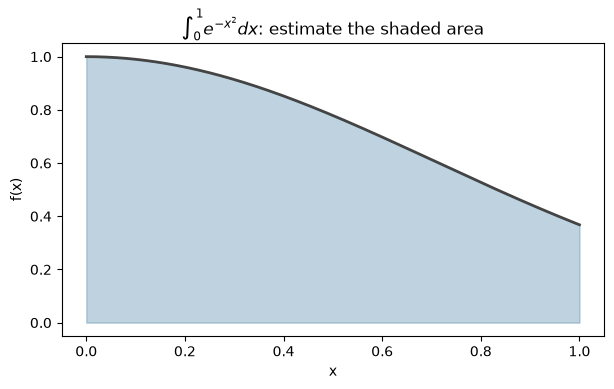

In [7]:
fig = plot_function_under_curve(
    lambda x: np.exp(-(x**2)), 0.0, 1.0, r"$\int_0^1 e^{-x^2}dx$: estimate the shaded area"
)
print(save_figure(fig, "04_integral_region"))

In [8]:
gaussian_truth = float(np.sqrt(np.pi) / 2 * special.erf(1.0))
gaussian_mc = integrate(lambda x: np.exp(-(x**2)), 0.0, 1.0, mc.n_darts, rng)

print(f"Monte Carlo : {gaussian_mc.value:.6f} +/- {gaussian_mc.se:.6f}")
print(f"exact       : {gaussian_truth:.6f}   (via the error function)")
print(f"error       : {gaussian_mc.value - gaussian_truth:+.6f}  "
      f"({abs(gaussian_mc.value - gaussian_truth) / gaussian_mc.se:.2f} se)")

Monte Carlo : 0.746428 +/- 0.000450
exact       : 0.746824   (via the error function)
error       : -0.000396  (0.88 se)


One more, where the exact answer is known so we can check the method rather than trust it:
$\int_0^\pi \sin(x)\,dx = 2$.

In [9]:
sine_mc = integrate(np.sin, 0.0, float(np.pi), mc.n_darts, rng)
print(f"Monte Carlo : {sine_mc.value:.6f} +/- {sine_mc.se:.6f}")
print(f"exact       : 2.000000")
print(f"error       : {sine_mc.value - 2.0:+.6f}  "
      f"({abs(sine_mc.value - 2.0) / sine_mc.se:.2f} se)")

Monte Carlo : 2.001064 +/- 0.002163
exact       : 2.000000
error       : +0.001064  (0.49 se)


## Expectations

The same machinery computes $E[f(X)]$ for any $X$ you can sample and any $f$ you can
evaluate — no matter how ugly $f$ is. Here $X \sim N(0,1)$ and we want $E[X^2]$, which is
1, and $E[|X|]$, which is $\sqrt{2/\pi}$.

In [10]:
def standard_normal(n: int, r: np.random.Generator) -> np.ndarray:
    return r.normal(0.0, 1.0, size=n)


second_moment = expectation(lambda x: x**2, standard_normal, mc.n_darts, rng)
abs_moment = expectation(np.abs, standard_normal, mc.n_darts, rng)
abs_truth = float(np.sqrt(2 / np.pi))

print(f"E[X^2] : {second_moment.value:.6f} +/- {second_moment.se:.6f}   (exact 1.000000)")
print(f"E[|X|] : {abs_moment.value:.6f} +/- {abs_moment.se:.6f}   (exact {abs_truth:.6f})")

E[X^2] : 1.005750 +/- 0.003187   (exact 1.000000)
E[|X|] : 0.798086 +/- 0.001347   (exact 0.797885)


## Saving the results

In [11]:
results = {
    "notebook": "04_monte_carlo",
    "seed": settings.seed,
    "n_darts": mc.n_darts,
    "n_replicates": mc.n_replicates,
    "pi": {
        "estimate": result.value,
        "truth": float(np.pi),
        "error": result.value - float(np.pi),
        "standard_error": result.se,
        "errors_in_se": abs(result.value - float(np.pi)) / result.se,
    },
    "convergence": {
        "fitted_log_log_slope": slope,
        "theoretical_slope": -0.5,
        "checkpoints": checkpoints.tolist(),
        "rmse": rmse.tolist(),
        "cost_of_accuracy": {"10x_accuracy": 100, "100x_accuracy": 10000},
    },
    "integrals": {
        "gaussian_0_to_1": {
            "estimate": gaussian_mc.value,
            "standard_error": gaussian_mc.se,
            "truth": gaussian_truth,
            "error": gaussian_mc.value - gaussian_truth,
        },
        "sine_0_to_pi": {
            "estimate": sine_mc.value,
            "standard_error": sine_mc.se,
            "truth": 2.0,
            "error": sine_mc.value - 2.0,
        },
    },
    "expectations": {
        "E_X_squared": {
            "estimate": second_moment.value,
            "standard_error": second_moment.se,
            "truth": 1.0,
        },
        "E_abs_X": {
            "estimate": abs_moment.value,
            "standard_error": abs_moment.se,
            "truth": abs_truth,
        },
    },
    "findings": [
        f"{mc.n_darts:,} darts estimated pi as {result.value:.5f} "
        f"(error {result.value - float(np.pi):+.5f}).",
        f"The measured log-log error slope was {slope:.3f}, against a theoretical -0.5.",
        "Accuracy costs quadratically: 10x more accuracy needs 100x more samples.",
        "An integral with no elementary antiderivative was evaluated to 4 decimal places.",
        "The same estimator handles areas, integrals and expectations without modification.",
    ],
    "figures": [
        "04_darts",
        "04_pi_convergence",
        "04_error_rate",
        "04_integral_region",
    ],
}
print(save_results("04_monte_carlo", results))

/workspaces/sampling_101/outputs/results/04_monte_carlo.json


## What this bought you

- **Monte Carlo turns computation into sampling.** Draw, evaluate, average. It works for
  areas, integrals, probabilities and expectations with the same three lines.
- It does not care about dimension. A 50-dimensional integral is the same code, which is
  why it is the only practical option in high dimensions.
- **The cost is $1/\sqrt{n}$**, measured here at a slope of about $-0.5$. Budget for it:
  another decimal place costs 100x the compute.
- Always report the standard error. It comes free from the same samples.

That $1/\sqrt{n}$ wall is the motivation for what comes next. If an event is rare enough,
no affordable $n$ will ever produce a single observation of it — and then plain Monte
Carlo does not converge slowly, it fails completely.

Next: [05 — Importance Sampling](05_importance_sampling.ipynb).